# Citi Bike Demand Intelligence
### Etapa 03 · Predicción de demanda horaria con Machine Learning

**Industria:** movilidad urbana / *bike sharing* · **Período:** NYC, 2024 · **Audiencia:** operaciones, analistas y evaluadores de Data Science

> **Pregunta ejecutiva:** ¿podemos anticipar cuántos viajes comenzarán en una hora futura y comprobar si los pronósticos meteorológicos aportan precisión adicional?

Este notebook continúa la adquisición de datos (01) y el EDA (02). Su resultado es un experimento retrospectivo de **regresión supervisada**, no un servicio de predicción en vivo.

**Lectura sugerida:** 1) resumen ejecutivo → 2) diseño y datos → 3) modelos → 4) impacto del clima → 5) evaluación final → 6) decisiones y límites.

## 1 · Resumen ejecutivo

Los resultados siguientes provienen de la **ejecución del notebook original aportado el 25/11/2026**. Se incluyen como referencia editorial; **no fueron recalculados durante esta revisión**. Los gráficos y tablas posteriores se generan al volver a ejecutar el notebook completo.

| Indicador | Resultado registrado |
|:--|--:|
| Viajes originales procesados | **44.302.480** |
| Observaciones útiles para modelado | **8.335 horas** |
| Mejor MAE en test (GB sin clima) | **609,17 viajes/hora** |
| Mejor RMSE en test (GB con clima) | **943,70 viajes/hora** |
| MAE baseline semanal en test | 1.378,97 viajes/hora |
| MAE con lluvia pronosticada en test · sin / con clima | **1.002,35 / 658,27** |

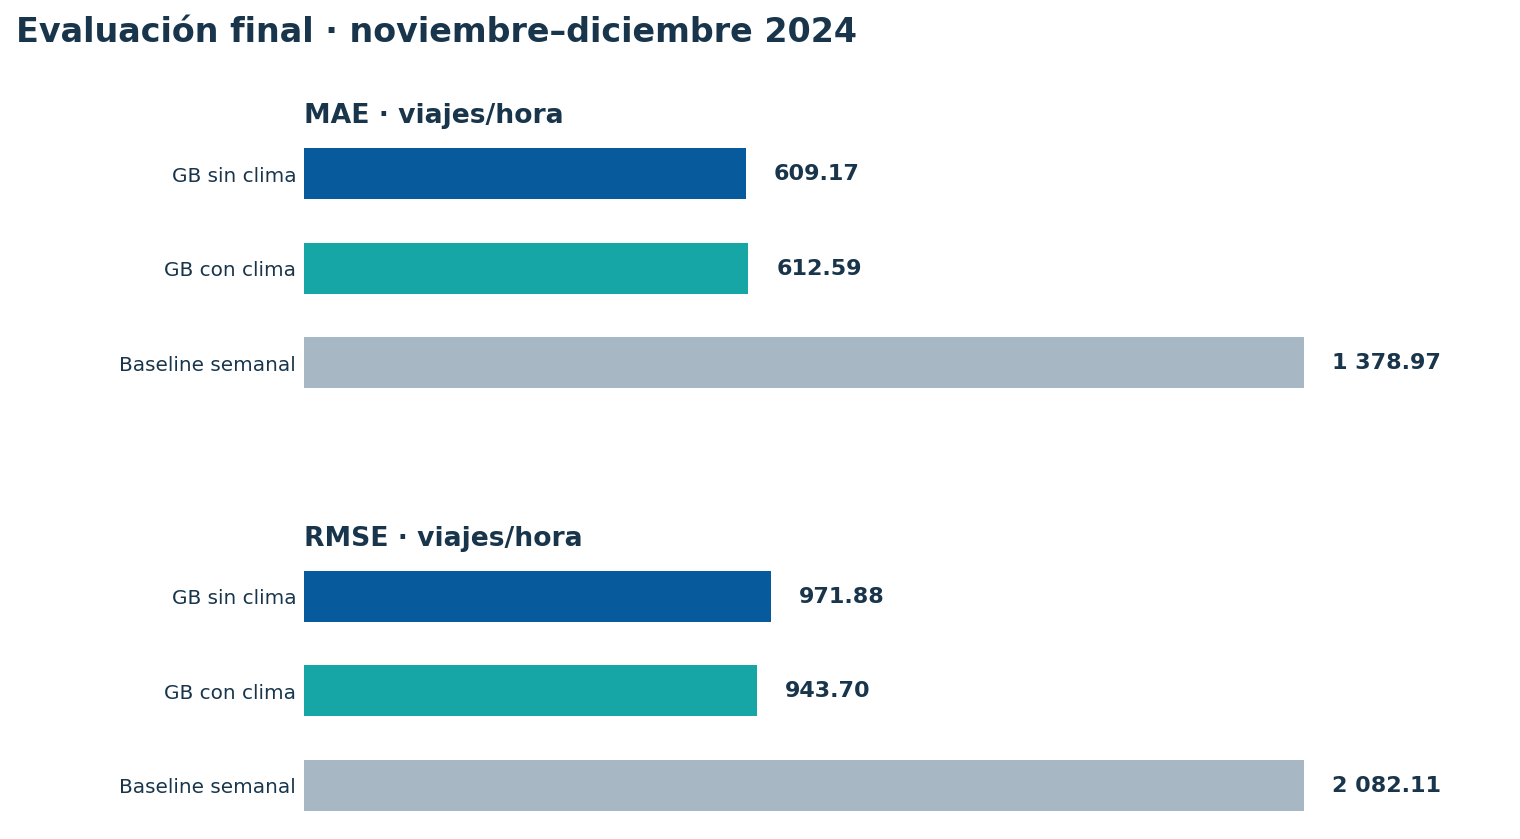

**Lectura para negocio.** Los modelos ensemble superan a repetir la misma hora de la semana anterior. Agregar pronósticos no mejora el MAE global del test, pero reduce el RMSE y muestra una mejora importante durante las horas con lluvia pronosticada. **Esto no demuestra disponibilidad de bicicletas por estación ni ahorro operativo realizado.**

## 2 · Abstract, motivación y problema de negocio

**Motivación.** Citi Bike registra patrones fuertes de hora, tipo de día y condiciones meteorológicas. El EDA del notebook `02_eda_insights.ipynb` documentó esas asociaciones. Ahora evaluamos si permiten **pronosticar el número de viajes iniciados** con información que, en principio, podría conocerse antes de la hora objetivo.

**Audiencia.** Equipos de planificación y analistas de operaciones. El pronóstico agregado puede ayudar a anticipar carga del sistema; sin datos de inventario, capacidad y flujos por estación **no predice desabastecimientos ni reposicionamientos específicos**.

**Problema de ML.** Regresión supervisada: `ride_count` es el número de inicios de viaje en el intervalo horario objetivo. Métrica primaria: **MAE** (viajes). Métrica complementaria: **RMSE**, más sensible a errores grandes. Baselines históricos y tres algoritmos ML.

**Hipótesis contrastable.** Añadir temperatura, precipitación y viento **pronosticados** ¿mejora el desempeño frente a usar solamente calendario y demanda pasada?

**Nota de horizonte (importante).** Para un intervalo objetivo de **15:00–16:00** local, emitimos la predicción a las **14:00**, una hora antes de que comience. Suponemos que el conteo 13:00–14:00 ya fue publicado. Es una simulación retrospectiva con esa disponibilidad supuesta.

## 3 · Diseño temporal y controles contra *data leakage*

| Evento | Ejemplo local NY | ¿Disponible al predecir a las 14:00? |
|:--|:--|:--|
| Demanda 13:00–14:00 (`lag_2h`) | Ya terminó | Sí, **si** el conteo se publica inmediatamente |
| Demanda 14:00–15:00 (`lag_1h`) | En transcurso | **No** |
| Demanda objetivo 15:00–16:00 | Aún no comenzó | **No**, es la variable a predecir |
| Temperatura y viento `previous_day1` | Pronóstico para 15:00 | Sí bajo anticipación nominal de 24 h; falta hora exacta de publicación |
| Precipitación `previous_day1` | Acumulado 15:00–16:00, etiqueta meteorológica 16:00 | Se alinea al intervalo; falta auditar el momento exacto de publicación |

**Precauciones:** los rezagos se calculan por *horas reales en UTC* (no con `shift` por filas), las dos 01:00 del regreso DST se tratan explícitamente y `TimeSeriesSplit` deja una fila de separación (`gap=1`) para evitar entrenar con la última etiqueta no conocida al emitir el pronóstico de la siguiente ventana.

**Alcance de la validación:** comprobamos la precedencia *nominal* de los pronósticos, **no** su timestamp real de publicación. Tampoco tenemos un feed de conteos horarios públicos garantizado en tiempo real.

## 4 · Fuentes, dependencias y ejecución

- **Citi Bike System Data:** [fuente oficial](https://citibikenyc.com/system-data); se utiliza el CSV procesado en `data/processed/citibike_analysis_hourly_2024.csv` (no se vuelven a descargar los 44,3 millones de viajes).
- **Open-Meteo Previous Runs:** [documentación oficial](https://open-meteo.com/en/docs/previous-runs-api); NOAA `gfs_global`, horizonte `previous_day1`, tres variables seleccionadas.
- **Histórico observado del EDA:** se conserva para el análisis descriptivo, **no** se utiliza como clima futuro en los modelos.

**Reproducibilidad.** Ejecutar desde la raíz del repositorio o `notebooks/`. En Google Colab, si no está el dataset, el primer bloque clona el repositorio público. Requiere conexión para la primera descarga de Open-Meteo; las siguientes ejecuciones reutilizan una **caché CSV**. Dependencias mínimas: `pandas`, `numpy`, `requests`, `scikit-learn`, `matplotlib`, `jupyter`.

**Orden:** Kernel → Restart & Run All. Mantener el test final reservado: **no usar sus métricas para realizar nuevas búsquedas de hiperparámetros**.

In [ ]:
# Un solo bloque de imports y configuración para todo el notebook.
from pathlib import Path
from IPython.display import display
from sklearn.model_selection import TimeSeriesSplit, cross_validate, RandomizedSearchCV
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import Ridge
from sklearn.ensemble import RandomForestRegressor, HistGradientBoostingRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error
from sklearn.inspection import permutation_importance
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import requests
import subprocess

plt.rcParams.update({"figure.dpi": 115, "axes.spines.top": False, "axes.spines.right": False, "axes.titleweight": "bold", "axes.grid": False})
COLORS = {"actual": "#18354b", "base": "#97a8b6", "ml": "#075b9c", "weather": "#16a6a5", "alert": "#e68b52"}
SEED = 42
NY_TZ = "America/New_York"
API_URL = "https://previous-runs-api.open-meteo.com/v1/forecast"
FORECAST_FIELDS = ["temperature_2m_previous_day1", "precipitation_previous_day1", "wind_speed_10m_previous_day1"]
RELATIVE_CSV = Path("data/processed/citibike_analysis_hourly_2024.csv")

# Buscamos la carpeta correcta sin forzar que Colab sea el único entorno.
paths = [Path.cwd(), *Path.cwd().parents, Path("/content/citi-bike-demand-intelligence")]
ROOT = next((p for p in paths if (p / RELATIVE_CSV).is_file()), None)
if ROOT is None and Path("/content").is_dir():
    # Únicamente en Colab, si todavía no está el repositorio.
    target = Path("/content/citi-bike-demand-intelligence")
    if not target.exists():
        subprocess.run(["git", "clone", "https://github.com/benitezlucio/citi-bike-demand-intelligence.git", str(target)], check=True)
    ROOT = target if (target / RELATIVE_CSV).is_file() else None
if ROOT is None:
    raise FileNotFoundError("No se encontró el CSV procesado. Cloná el repositorio y ejecutá desde su raíz o notebooks/.")
DATA_PATH = ROOT / RELATIVE_CSV
CACHE = ROOT / "data/processed/citibike_gfs_previous_day1_2024.csv"
print("Repositorio:", ROOT)
print("Dataset:", DATA_PATH)

## 5 · Auditoría de datos y EDA breve

El EDA exhaustivo y sus seis hipótesis ya están documentados en la Etapa 02. Aquí revisamos calidad, distribución del objetivo y patrones esenciales para el modelado. Las variables meteorológicas **observadas** del CSV no se incorporan a `X`.

In [ ]:
# Revisamos cantidad de filas, rango y calidad, sin alterar la fuente.
df = pd.read_csv(DATA_PATH, parse_dates=["datetime"]).sort_values("datetime").reset_index(drop=True)
assert {"datetime", "ride_count"}.issubset(df.columns)
assert df["datetime"].is_unique and df["datetime"].notna().all()
assert df["ride_count"].notna().all() and (df["ride_count"] >= 0).all()
assert df["datetime"].min() == pd.Timestamp("2024-01-01 00:00")
assert df["datetime"].max() == pd.Timestamp("2024-12-31 23:00")
print("Dimensiones:", df.shape, "| Viajes:", format(df["ride_count"].sum(), ","))
print("Nulos:", int(df.isna().sum().sum()), "| Rango:", df["datetime"].min(), "a", df["datetime"].max())
labels_esperadas = pd.date_range("2024-01-01", "2024-12-31 23:00", freq="h")
print("Horas locales inexistentes:", labels_esperadas.difference(df["datetime"]).tolist())
print("Fila 01:00 repetida de noviembre:", int((df["datetime"] == pd.Timestamp("2024-11-03 01:00")).sum()))
display(df[["datetime", "ride_count"]].head(3))

In [ ]:
# Dos gráficos compactos del EDA: forma horaria y evolución mensual.
eda = df.assign(hour=df["datetime"].dt.hour, month=df["datetime"].dt.month, weekend=df["datetime"].dt.dayofweek >= 5)
perfil = eda.groupby(["weekend", "hour"])["ride_count"].mean().unstack(0)
por_mes = eda.groupby("month")["ride_count"].mean()
fig, ax = plt.subplots(1, 2, figsize=(13, 3.5))
ax[0].plot(perfil.index, perfil[False], label="Laborables", color=COLORS["ml"], lw=2.5)
ax[0].plot(perfil.index, perfil[True], label="Fin de semana", color=COLORS["weather"], lw=2.5)
ax[0].set(title="Demanda según hora y tipo de día", xlabel="Hora local", ylabel="Viajes medios por hora")
ax[0].legend(frameon=False)
ax[1].bar(por_mes.index, por_mes.values, color=COLORS["ml"], alpha=.85)
ax[1].set(title="Demanda media por hora, por mes", xlabel="Mes de 2024", ylabel="Viajes medios por hora")
ax[1].set_xticks(range(1, 13))
for a in ax: a.grid(axis="y", alpha=.17)
fig.tight_layout(); plt.show()

## 6 · Pronósticos históricos y cobertura

Descargamos GFS con tres pronósticos etiquetados `previous_day1`: temperatura, precipitación y viento. La primera ejecución necesita internet; el resultado se guarda en caché para evitar 13 consultas redundantes al volver a ejecutar.

**Auditoría previa (ejecución original):** 8.784 horas reales locales en 2024; 8.345 con las tres variables meteorológicas y 439 incompletas. Primer pronóstico completo: **19/01/2024 07:00, Nueva York**. Este resumen debe volver a verificarse con el código.

In [ ]:
# Descargamos una vez y reutilizamos un cache local en siguientes ejecuciones.
if CACHE.exists():
    forecast_anual = pd.read_csv(CACHE)
    forecast_anual["datetime_utc"] = pd.to_datetime(forecast_anual["datetime_utc"], utc=True)
    print("Pronósticos leídos de caché:", CACHE)
else:
    periodos = [(mes.start_time.strftime("%Y-%m-%d"), mes.end_time.strftime("%Y-%m-%d"))
                for mes in pd.period_range("2024-01", "2024-12", freq="M")]
    periodos.append(("2025-01-01", "2025-01-01"))  # Horas UTC que aún pertenecen a 2024 en NY.
    partes = []
    for inicio, fin in periodos:
        params = {"latitude": 40.7128, "longitude": -74.0060,
                  "start_date": inicio, "end_date": fin,
                  "hourly": ",".join(FORECAST_FIELDS), "models": "gfs_global",
                  "timezone": "GMT", "timeformat": "unixtime"}
        respuesta = requests.get(API_URL, params=params, timeout=90)
        respuesta.raise_for_status()
        bloque = pd.DataFrame(respuesta.json()["hourly"])
        assert set(FORECAST_FIELDS).issubset(bloque.columns), "Faltan campos meteorológicos"
        bloque["datetime_utc"] = pd.to_datetime(bloque["time"], unit="s", utc=True)
        partes.append(bloque[["datetime_utc", *FORECAST_FIELDS]])
        print("Descargado:", inicio, "→", fin)
    forecast_anual = pd.concat(partes, ignore_index=True)
    CACHE.parent.mkdir(parents=True, exist_ok=True)
    forecast_anual.to_csv(CACHE, index=False)
forecast_anual = forecast_anual.sort_values("datetime_utc").reset_index(drop=True)
assert forecast_anual["datetime_utc"].is_unique
forecast_anual["datetime_ny"] = forecast_anual["datetime_utc"].dt.tz_convert(NY_TZ)
forecast_2024 = forecast_anual.loc[forecast_anual["datetime_ny"].dt.year == 2024].copy()
forecast_2024["completa"] = forecast_2024[FORECAST_FIELDS].notna().all(axis=1)
forecast_2024["mes"] = forecast_2024["datetime_ny"].dt.strftime("%Y-%m")
resumen_anual = forecast_2024.groupby("mes")["completa"].agg(horas_totales="size", horas_completas="sum")
resumen_anual["cobertura_pct"] = 100 * resumen_anual["horas_completas"] / resumen_anual["horas_totales"]
print("Horas reales:", len(forecast_2024), "| Completas:", int(forecast_2024["completa"].sum()))
print("Primera hora completa:", forecast_2024.loc[forecast_2024["completa"], "datetime_ny"].min())
display(resumen_anual.round(2))

In [ ]:
# La cobertura es 100 % de febrero a diciembre en la ejecución original.
fig, ax = plt.subplots(figsize=(12, 3.2))
meses = [m[-2:] for m in resumen_anual.index]
ax.bar(meses, resumen_anual["cobertura_pct"], color=[COLORS["alert"] if v < 99.9 else COLORS["weather"] for v in resumen_anual["cobertura_pct"]])
ax.set_ylim(0, 112); ax.set(title="Cobertura de pronósticos históricos (GFS previous_day1)", xlabel="Mes de 2024", ylabel="Horas completas (%)")
for i, v in enumerate(resumen_anual["cobertura_pct"]): ax.text(i, v + 1.3, f"{v:.0f}%", ha="center", fontsize=9)
ax.grid(axis="y", alpha=.18)
fig.tight_layout(); plt.show()

## 7 · Alineación temporal, DST y dataset de modelado

La tabla de viajes usa el **inicio del intervalo** horario. Para la temperatura y el viento empleamos el pronóstico válido al inicio; para la precipitación (acumulación de la hora anterior al timestamp meteorológico) desplazamos su etiqueta una hora hacia atrás.

El 03/11/2024 la fuente de viajes consolidó dos horas reales 01:00 en una sola etiqueta local. **Excluimos únicamente esa etiqueta del experimento** y dejamos constancia de los rezagos que faltan por esa exclusión. No modificamos el dataset original.

In [ ]:
# Resolvemos la hora local ambigua de noviembre antes de generar UTC.
HORA_AMBIGUA = pd.Timestamp("2024-11-03 01:00")
rides_validos = df.loc[df["datetime"] != HORA_AMBIGUA, ["datetime", "ride_count"]].copy()
rides_validos["target_start_utc"] = rides_validos["datetime"].dt.tz_localize(NY_TZ).dt.tz_convert("UTC")
assert rides_validos["target_start_utc"].is_unique

# Los campos instantáneos y la precipitación horaria usan etiquetas distintas.
instantes = forecast_anual[["datetime_utc", "temperature_2m_previous_day1", "wind_speed_10m_previous_day1"]].rename(columns={
    "datetime_utc": "target_start_utc", "temperature_2m_previous_day1": "forecast_temp", "wind_speed_10m_previous_day1": "forecast_wind"})
lluvia = forecast_anual[["datetime_utc", "precipitation_previous_day1"]].copy()
lluvia["target_start_utc"] = lluvia["datetime_utc"] - pd.Timedelta(hours=1)
lluvia = lluvia[["target_start_utc", "precipitation_previous_day1"]].rename(columns={"precipitation_previous_day1": "forecast_precipitation"})

features_clima = ["forecast_temp", "forecast_wind", "forecast_precipitation"]
dataset_ml = rides_validos.merge(instantes, on="target_start_utc", how="left", validate="one_to_one").merge(
    lluvia, on="target_start_utc", how="left", validate="one_to_one")
dataset_ml["weather_complete"] = dataset_ml[features_clima].notna().all(axis=1)
ml_validado = dataset_ml.loc[dataset_ml["weather_complete"]].copy()

# Declaramos cuándo se predice y cuándo se conoce el último intervalo de demanda.
ml_validado["prediction_time_utc"] = ml_validado["target_start_utc"] - pd.Timedelta(hours=1)
ml_validado["last_known_hour_utc"] = ml_validado["target_start_utc"] - pd.Timedelta(hours=2)
ml_validado["temp_forecast_reference_utc"] = ml_validado["target_start_utc"] - pd.Timedelta(hours=24)
ml_validado["rain_forecast_reference_utc"] = ml_validado["target_start_utc"] + pd.Timedelta(hours=1) - pd.Timedelta(hours=24)
assert (ml_validado["last_known_hour_utc"] < ml_validado["prediction_time_utc"]).all()
assert (ml_validado["temp_forecast_reference_utc"] < ml_validado["prediction_time_utc"]).all()
assert (ml_validado["rain_forecast_reference_utc"] < ml_validado["prediction_time_utc"]).all()
assert ml_validado["target_start_utc"].is_unique
print("Viajes (sin hora ambigua):", len(rides_validos))
print("Filas con pronóstico completo:", len(ml_validado))
print("Horas sin clima:", int((~dataset_ml["weather_complete"]).sum()))

In [ ]:
# Ingeniería de atributos: calendario y demanda histórica conocida antes de predecir.
ml_features = ml_validado.copy()
historico = rides_validos.set_index("target_start_utc")["ride_count"].sort_index()
ml_features["hour"] = ml_features["datetime"].dt.hour
ml_features["day_of_week"] = ml_features["datetime"].dt.dayofweek
ml_features["month"] = ml_features["datetime"].dt.month
ml_features["is_weekend"] = (ml_features["day_of_week"] >= 5).astype(int)
for nombre, ciclo, numero in [("hour", 24, ml_features["hour"]), ("dow", 7, ml_features["day_of_week"]),
                             ("month", 12, ml_features["month"] - 1)]:
    ml_features[f"{nombre}_sin"] = np.sin(2 * np.pi * numero / ciclo)
    ml_features[f"{nombre}_cos"] = np.cos(2 * np.pi * numero / ciclo)

# Usamos timedelta exacto en UTC; nunca shift por cantidad de filas.
for horas in [2, 3, 4, 24, 168]:
    ml_features[f"lag_{horas}h"] = (ml_features["target_start_utc"] - pd.Timedelta(hours=horas)).map(historico)
ml_features["rolling_mean_3h"] = ml_features[["lag_2h", "lag_3h", "lag_4h"]].mean(axis=1, skipna=False)
features_historicas = ["lag_2h", "lag_3h", "lag_24h", "lag_168h", "rolling_mean_3h"]
ml_features["historico_completo"] = ml_features[features_historicas].notna().all(axis=1)
incompletas = ml_features.loc[~ml_features["historico_completo"], ["datetime", *features_historicas]].copy()
ml_ready = ml_features.loc[ml_features["historico_completo"]].sort_values("target_start_utc").reset_index(drop=True)

features_sin_clima = ["hour_sin", "hour_cos", "dow_sin", "dow_cos", "month_sin", "month_cos", "is_weekend", "lag_2h", "lag_3h", "lag_24h", "lag_168h", "rolling_mean_3h"]
features_con_clima = features_sin_clima + features_clima
assert ml_ready["target_start_utc"].is_unique and ml_ready["target_start_utc"].is_monotonic_increasing
assert not ml_ready[features_con_clima + ["ride_count"]].isna().any().any()
print("Filas con clima:", len(ml_validado), "| Filas descartadas por rezagos:", len(incompletas), "| Dataset final:", ml_ready.shape)
display(incompletas[["datetime"]].assign(motivo="Rezagos faltantes por hora DST excluida"))

## 8 · Evaluación: mantener el futuro fuera del entrenamiento

Separamos **enero–agosto** para entrenar, **septiembre–octubre** para seleccionar modelos y **noviembre–diciembre** como test reservado. Los baselines y modelos utilizan los mismos registros de evaluación.

Durante validación/test se presupone un escenario de **actualización hora a hora**: los rezagos pueden provenir de horas reales ya terminadas aunque estén dentro del período evaluado. No estamos simulando un único pronóstico de 61 días realizado en septiembre.

La última etiqueta del entrenamiento se excluye si no habría terminado antes de la primera predicción. Dentro de validación cruzada usamos `gap=1` (una fila de separación). El criterio exacto en el salto de períodos se comprueba con timestamps UTC.

In [ ]:
# Particiones cronológicas, sin mezcla aleatoria.
train = ml_ready.loc[ml_ready["datetime"] < "2024-09-01"].copy()
val = ml_ready.loc[(ml_ready["datetime"] >= "2024-09-01") & (ml_ready["datetime"] < "2024-11-01")].copy()
test = ml_ready.loc[ml_ready["datetime"] >= "2024-11-01"].copy()
assert len(train) + len(val) + len(test) == len(ml_ready)
assert train["target_start_utc"].max() < val["target_start_utc"].min() < test["target_start_utc"].min()

# Un registro de entrenamiento cuya demanda terminaría al iniciar la predicción
# se excluye por precaución; solo se usan etiquetas disponibles hasta ese momento.
primera_pred_val = val["prediction_time_utc"].min()
train_seguro = train.loc[train["target_start_utc"] + pd.Timedelta(hours=1) <= primera_pred_val].copy()
cv = TimeSeriesSplit(n_splits=4, gap=1)
X_train = train_seguro[features_sin_clima]; y_train = train_seguro["ride_count"]
X_val = val[features_sin_clima]; y_val = val["ride_count"]
print("Train original:", len(train), "| Entrenamiento utilizable:", len(train_seguro), "| Validación:", len(val), "| Test reservado:", len(test))

## 9 · Baselines y modelos: de lo simple a lo complejo

**Antes de comparar ML**, necesitamos una regla de referencia. Los baselines repiten la última hora completa conocida (`lag_2h`), el intervalo equivalente de hace 24 h (`lag_24h`) o de hace 168 h (`lag_168h`).

**Qué esperamos del ML:** reducir errores frente a esas reglas. Un algoritmo más complejo **no es automáticamente mejor**: necesita demostrarlo en datos futuros.

In [ ]:
# Referencias sin entrenamiento; evaluación solo en validación.
baselines = {"Persistencia": "lag_2h", "Estacional diario": "lag_24h", "Estacional semanal": "lag_168h"}
resultados_baseline = pd.DataFrame([
    {"Modelo": nombre, "MAE": mean_absolute_error(y_val, val[col]),
     "RMSE": np.sqrt(mean_squared_error(y_val, val[col]))}
    for nombre, col in baselines.items()
]).sort_values("MAE").reset_index(drop=True)
display(resultados_baseline.round(2))

### 9.1 · ¿En qué se diferencian los algoritmos?

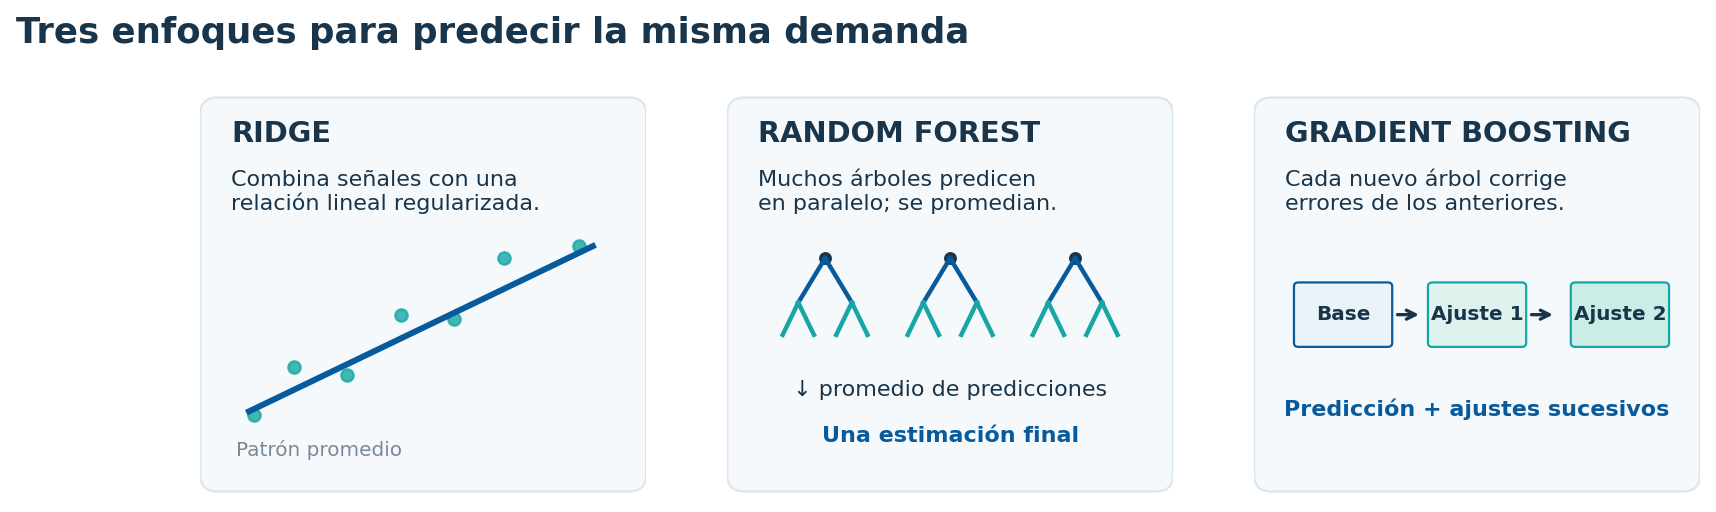

- **Ridge:** relación lineal regularizada, con escalado dentro del `Pipeline` (sirve como referencia interpretable).
- **Random Forest:** muchos árboles en paralelo, cuyas predicciones se agregan.
- **Gradient Boosting:** árboles sucesivos que corrigen parte de los errores anteriores.

*Los dibujos son esquemas pedagógicos: no muestran los árboles reales entrenados ni implican que un modelo sea mejor por su forma.*

In [ ]:
# Entrenamos los tres modelos con las mismas variables, filas y folds cronológicos.
modelos = {
    "Ridge": Pipeline([("scaler", StandardScaler()), ("modelo", Ridge(alpha=10.0))]),
    "Random Forest": RandomForestRegressor(n_estimators=200, max_depth=16, min_samples_leaf=5, random_state=SEED, n_jobs=2),
    "Gradient Boosting": HistGradientBoostingRegressor(max_iter=250, learning_rate=0.05, max_leaf_nodes=15,
                       min_samples_leaf=20, l2_regularization=1.0, early_stopping=False, random_state=SEED)
}
cv_modelos = {}; pred_modelos = {}; resultados_ml = []
for nombre, modelo in modelos.items():
    scores = cross_validate(modelo, X_train, y_train, cv=cv,
                            scoring={"mae": "neg_mean_absolute_error", "rmse": "neg_root_mean_squared_error"})
    modelo.fit(X_train, y_train)
    pred = modelo.predict(X_val)
    cv_modelos[nombre] = -scores["test_mae"]
    pred_modelos[nombre] = pred
    resultados_ml.append({"Modelo": nombre, "MAE_CV": -scores["test_mae"].mean(),
                          "RMSE_CV": -scores["test_rmse"].mean(),
                          "MAE": mean_absolute_error(y_val, pred),
                          "RMSE": np.sqrt(mean_squared_error(y_val, pred)),
                          "Predicciones_negativas": int((pred < 0).sum())})
resultados_ml = pd.DataFrame(resultados_ml)
comparacion_modelos_val = pd.concat([resultados_baseline, resultados_ml[["Modelo", "MAE", "RMSE"]]], ignore_index=True).sort_values("MAE")
print("Comparación de modelos · validación septiembre–octubre")
display(comparacion_modelos_val.round(2))
print("CV cronológica (solo ML):")
display(resultados_ml[["Modelo", "MAE_CV", "RMSE_CV", "Predicciones_negativas"]].round(2))

In [ ]:
# Un gráfico único para stakeholders: menor error significa mejor predicción.
fig, ax = plt.subplots(1, 2, figsize=(12.8, 4.1))
orden = comparacion_modelos_val.sort_values("MAE").reset_index(drop=True)
for a, metrica in zip(ax, ["MAE", "RMSE"]):
    colores = [COLORS["ml"] if "Boosting" in n else COLORS["base"] if "Estacional" in n or "Persistencia" in n else COLORS["weather"] for n in orden["Modelo"]]
    a.barh(orden["Modelo"], orden[metrica], color=colores)
    a.invert_yaxis(); a.set(title=f"{metrica} · validación", xlabel="Viajes por hora (menor es mejor)")
    a.grid(axis="x", alpha=.15)
fig.tight_layout(); plt.show()

## 10 · Optimización de hiperparámetros

Exploramos combinaciones de complejidad, regularización y tasa de aprendizaje de Gradient Boosting con `RandomizedSearchCV`, dentro de los datos de entrenamiento. **Los parámetros óptimos por CV no tienen por qué mejorar el período de validación externa**.

En la ejecución original, la búsqueda obtuvo MAE 785,12 frente a 738,80 de la configuración inicial (comparaciones con pequeñas diferencias de protocolo). Se conservó la configuración inicial como candidata; **no se alteró después de consultar el test**.

In [ ]:
# La búsqueda prueba 15 configuraciones y respeta el orden temporal.
parametros = {"max_iter": [150, 250, 350], "learning_rate": [0.03, 0.05, 0.08],
              "max_leaf_nodes": [7, 15, 31], "min_samples_leaf": [10, 20, 40],
              "l2_regularization": [0.0, 1.0, 5.0]}
busqueda_gb = RandomizedSearchCV(
    HistGradientBoostingRegressor(early_stopping=False, random_state=SEED),
    param_distributions=parametros, n_iter=15, scoring="neg_mean_absolute_error",
    cv=TimeSeriesSplit(n_splits=4, gap=1), random_state=SEED, n_jobs=2, refit=True)
busqueda_gb.fit(X_train, y_train)
pred_opt = busqueda_gb.best_estimator_.predict(X_val)
res_opt = {"MAE_val": mean_absolute_error(y_val, pred_opt),
           "RMSE_val": np.sqrt(mean_squared_error(y_val, pred_opt))}
print("Mejores parámetros por CV:", busqueda_gb.best_params_)
print("MAE CV de la búsqueda:", round(-busqueda_gb.best_score_, 2))
print("Validación del modelo optimizado:", {k: round(v, 2) for k,v in res_opt.items()})

## 11 · Experimento central: ¿qué aporta el pronóstico meteorológico?

Ahora comparamos **el mismo Gradient Boosting** con exactamente las mismas fechas e hiperparámetros: una versión con 12 atributos de calendario y demanda histórica frente a otra con esas 12 variables más temperatura, precipitación y viento pronosticados. Es una **ablación**: aislamos la utilidad de un grupo de variables sin cambiar el algoritmo.

In [ ]:
# Configuración fija elegida con la validación; no modificaremos el test para optimizarla.
def nuevo_gradient_boosting():
    return HistGradientBoostingRegressor(max_iter=250, learning_rate=0.05, max_leaf_nodes=15,
            min_samples_leaf=20, l2_regularization=1.0, early_stopping=False, random_state=SEED)

modelos_clima = {}; predicciones_val = {}; resultados_clima = []
for nombre, cols in {"Sin clima": features_sin_clima, "Con clima": features_con_clima}.items():
    m = nuevo_gradient_boosting()
    X_tr = train_seguro[cols]; X_va = val[cols]
    scores = cross_validate(m, X_tr, y_train, cv=cv,
                            scoring={"mae": "neg_mean_absolute_error", "rmse": "neg_root_mean_squared_error"})
    m.fit(X_tr, y_train)
    pred = m.predict(X_va)
    modelos_clima[nombre] = m; predicciones_val[nombre] = pred
    resultados_clima.append({"Modelo": nombre, "MAE_CV": -scores["test_mae"].mean(),
                             "RMSE_CV": -scores["test_rmse"].mean(), "MAE_val": mean_absolute_error(y_val, pred),
                             "RMSE_val": np.sqrt(mean_squared_error(y_val, pred))})
comparacion_clima = pd.DataFrame(resultados_clima)
display(comparacion_clima.round(2))
mae_sin = comparacion_clima.loc[comparacion_clima["Modelo"] == "Sin clima", "MAE_val"].iloc[0]
mae_con = comparacion_clima.loc[comparacion_clima["Modelo"] == "Con clima", "MAE_val"].iloc[0]
print(f"Reducción relativa del MAE al agregar clima: {(mae_sin-mae_con)/mae_sin*100:.2f}%")

In [ ]:
# Comparamos las predicciones para una semana fija; no elegida por su desempeño.
semana = val.loc[(val["datetime"] >= "2024-10-01") & (val["datetime"] < "2024-10-08")].copy()
assert not semana.empty
pos = val.index.get_indexer(semana.index)
fig, ax = plt.subplots(figsize=(13, 4.2))
ax.plot(semana["datetime"], semana["ride_count"], color=COLORS["actual"], lw=2.3, label="Demanda real")
ax.plot(semana["datetime"], predicciones_val["Sin clima"][pos], color=COLORS["ml"], alpha=.85, label="Sin clima")
ax.plot(semana["datetime"], predicciones_val["Con clima"][pos], color=COLORS["weather"], alpha=.85, label="Con clima")
ax.set(title="Una semana de demanda real y pronosticada · validación", xlabel="Fecha · octubre 2024", ylabel="Viajes iniciados / hora")
ax.grid(axis="y", alpha=.18);ax.legend(frameon=False,ncol=3)
fig.autofmt_xdate(); fig.tight_layout(); plt.show()

### 11.1 · ¿En qué circunstancias ayuda el clima?

**Segmentamos el error, no el entrenamiento.** Consideramos horas con lluvia pronosticada (`forecast_precipitation > 0`), franjas pico descriptivas (07–09 y 16–18), laborables y fines de semana. Los segmentos se solapan y **no se suman**. En validación original el clima mejoró el MAE global 4,64 %, pero empeoró durante 73 horas con lluvia; el diagnóstico fue exploratorio, no motivo para retocar parámetros usando el test.

In [ ]:
# Analizamos las diferencias dentro del mismo período de validación.
analisis_errores = val[["datetime", "ride_count", "forecast_precipitation", "is_weekend", "hour"]].copy()
analisis_errores["pred_sin_clima"] = predicciones_val["Sin clima"]
analisis_errores["pred_con_clima"] = predicciones_val["Con clima"]
for suf in ["sin_clima", "con_clima"]:
    analisis_errores[f"error_{suf}"] = (analisis_errores["ride_count"] - analisis_errores[f"pred_{suf}"]).abs()
analisis_errores["lluvia_pronosticada"] = analisis_errores["forecast_precipitation"] > 0
analisis_errores["hora_pico"] = analisis_errores["hour"].isin([7, 8, 9, 16, 17, 18])
escenarios = {"Todas": pd.Series(True, index=analisis_errores.index),
             "Con lluvia": analisis_errores["lluvia_pronosticada"],
             "Sin lluvia": ~analisis_errores["lluvia_pronosticada"],
             "Horas pico": analisis_errores["hora_pico"],
             "Otras horas": ~analisis_errores["hora_pico"],
             "Laborables": analisis_errores["is_weekend"] == 0,
             "Fin de semana": analisis_errores["is_weekend"] == 1}
res_esc = []
for nombre, mascara in escenarios.items():
    g = analisis_errores.loc[mascara]
    if len(g) == 0: continue
    a, b = g["error_sin_clima"].mean(), g["error_con_clima"].mean()
    res_esc.append({"Escenario": nombre, "Horas": len(g), "MAE sin clima": a, "MAE con clima": b,
                    "Mejora %": (a-b)/a*100})
resultados_escenarios = pd.DataFrame(res_esc)
display(resultados_escenarios.round(2))

In [ ]:
# Positivo = agregar clima redujo el MAE. Negativo = lo empeoró.
r = resultados_escenarios.loc[resultados_escenarios["Escenario"] != "Todas"].sort_values("Mejora %")
fig, ax = plt.subplots(figsize=(10.5, 4.1))
ax.barh(r["Escenario"], r["Mejora %"], color=[COLORS["weather"] if v > 0 else COLORS["alert"] for v in r["Mejora %"]])
ax.axvline(0, color=COLORS["actual"], lw=1)
ax.set(title="¿Cuándo ayuda el pronóstico? · Validación", xlabel="Reducción del MAE al agregar clima (%)")
ax.grid(axis="x", alpha=.15);fig.tight_layout();plt.show()

## 12 · Interpretabilidad: ¿de qué depende el modelo?

La **importancia por permutación** mide cuánto aumenta el MAE cuando desordenamos una columna manteniendo las demás. La calculamos con el modelo meteorológico **entrenado antes del test** sobre septiembre–octubre, para no volver a usar el test en el análisis de diseño.

Esto mide dependencia del modelo; **no demuestra causalidad**. Como los rezagos y las variables de calendario están correlacionados, tampoco conviene sumar importancias ni interpretarlas como porcentajes.

In [ ]:
# Permutation importance sobre validación, no sobre el test final.
importancias = permutation_importance(
    modelos_clima["Con clima"], val[features_con_clima], val["ride_count"],
    scoring="neg_mean_absolute_error", n_repeats=5, random_state=SEED, n_jobs=2)
tabla_importancia = pd.DataFrame({"Variable": features_con_clima,
                                  "Importancia_MAE": importancias.importances_mean,
                                  "Desviacion": importancias.importances_std}).sort_values("Importancia_MAE", ascending=False).reset_index(drop=True)
display(tabla_importancia.round(2))

In [ ]:
# Mostramos las diez variables de mayor dependencia predictiva.
top = tabla_importancia.head(10).sort_values("Importancia_MAE")
fig, ax = plt.subplots(figsize=(10.5, 5))
ax.barh(top["Variable"], top["Importancia_MAE"], xerr=top["Desviacion"],
        color=[COLORS["weather"] if nombre.startswith("forecast_") else COLORS["ml"] for nombre in top["Variable"]], capsize=2)
ax.set(title="Importancia predictiva · Gradient Boosting con clima", xlabel="Aumento del MAE al permutar (viajes / hora)")
ax.grid(axis="x", alpha=.17);fig.tight_layout();plt.show()

## 13 · Test final reservado · noviembre–diciembre

**Protocolo congelado:** sin modificar atributos, hiperparámetros ni modelos después de observar las métricas finales. Reentrenamos las dos variantes con enero–octubre, excluyendo la última etiqueta que no estaría disponible a la hora de la primera predicción del test.

**Elección por métrica primaria.** Entre las dos variantes, la menor MAE en test es de **GB sin clima**, mientras **GB con clima** reduce RMSE y errores durante lluvia. No se debe convertir el diagnóstico post-test en una nueva búsqueda de configuraciones.

In [ ]:
# Reentrenamiento final con el período de desarrollo; usamos test solo aquí.
desarrollo = pd.concat([train, val], ignore_index=True).sort_values("target_start_utc")
test_final = test.sort_values("target_start_utc").copy()
primera_prediccion_test = test_final["prediction_time_utc"].min()
desarrollo = desarrollo.loc[desarrollo["target_start_utc"] + pd.Timedelta(hours=1) <= primera_prediccion_test].copy()
assert desarrollo["target_start_utc"].max() < test_final["target_start_utc"].min()
y_test = test_final["ride_count"]
resultados_test = [{"Modelo": "Baseline semanal", "MAE": mean_absolute_error(y_test, test_final["lag_168h"]),
                    "RMSE": np.sqrt(mean_squared_error(y_test, test_final["lag_168h"]))}]
predicciones_test = {}
for nombre, columnas in {"Gradient Boosting sin clima": features_sin_clima,
                         "Gradient Boosting con clima": features_con_clima}.items():
    modelo = nuevo_gradient_boosting()
    modelo.fit(desarrollo[columnas], desarrollo["ride_count"])
    pred = modelo.predict(test_final[columnas])
    predicciones_test[nombre] = pred
    resultados_test.append({"Modelo": nombre, "MAE": mean_absolute_error(y_test, pred),
                             "RMSE": np.sqrt(mean_squared_error(y_test, pred))})
comparacion_test = pd.DataFrame(resultados_test).sort_values("MAE").reset_index(drop=True)
print("Train final:", len(desarrollo), "| Test:", len(test_final))
display(comparacion_test.round(2))

In [ ]:
# Dos métricas: MAE para el error típico; RMSE para penalizar errores grandes.
fig, ax = plt.subplots(1, 2, figsize=(12.5, 3.9))
for a, metrica in zip(ax, ["MAE", "RMSE"]):
    ord_ = comparacion_test.sort_values(metrica)
    colores = [COLORS["weather"] if "con clima" in n else COLORS["ml"] if "Boosting" in n else COLORS["base"] for n in ord_["Modelo"]]
    a.barh(ord_["Modelo"], ord_[metrica], color=colores)
    a.invert_yaxis();a.set(title=f"{metrica} · test reservado", xlabel="Viajes / hora (menor es mejor)")
    a.grid(axis="x", alpha=.15)
fig.tight_layout();plt.show()

# Desglose de lluvia previamente definido; no se usa para reentrenar.
llueve = test_final["forecast_precipitation"] > 0
print("Horas con lluvia pronosticada en test:", int(llueve.sum()))
for nombre, pred in predicciones_test.items():
    print(nombre, "MAE con lluvia:", round(mean_absolute_error(y_test.loc[llueve], pred[llueve.to_numpy()]), 2))

## 14 · Conclusiones para stakeholders y criterios de decisión

**Lo que sí indican los resultados del notebook original**

1. **Anticipación agregada factible:** Gradient Boosting reduce el MAE del test más del 55 % respecto de repetir la misma hora de la semana anterior. No implica precisión uniforme en todas las franjas.
2. **El clima no gana siempre:** el MAE global de noviembre–diciembre fue **609,17 sin clima** frente a **612,59 con clima**. El modelo meteorológico sí redujo RMSE (**943,70 vs. 971,88**) y el MAE durante 204 horas con lluvia pronosticada (**658,27 vs. 1.002,35**).
3. **La demanda reciente manda:** los rezagos y el horario dominaron la importancia por permutación; entre los pronósticos, temperatura aportó la mayor importancia individual en validación.
4. **Decisión sugerida:** adoptar **GB sin clima como referencia global por MAE**. Tratar GB con clima como **alternativa prometedora para operaciones sensibles a la lluvia**, no como sistema definitivamente superior. Requerirá validación externa adicional antes de una implementación real.

**No podemos inferir:** disponibilidad de bicicletas por estación, ahorro económico, efecto causal del clima ni desempeño futuro en otros años. La predicción asume conteos horarios disponibles inmediatamente y el uso de `previous_day1` con anticipación nominal, **sin una auditoría independiente de su publicación exacta**.

**Próximo desarrollo posible:** validar otro año, auditar timestamps de ejecución/publicación meteorológica, simular latencia real de conteos, modelar incertidumbre y evaluar utilidad operativa con responsables del sistema.

## 15 · Auditoría, reproducibilidad y alcance académico

### Controles incluidos

- [x] Problema de **regresión**, abstract y audiencia; variable objetivo `ride_count`.
- [x] EDA breve con distribución temporal y controles de faltantes.
- [x] Ingeniería de atributos (rezagos, media histórica, codificación cíclica); `StandardScaler` dentro del pipeline de Ridge.
- [x] **Tres modelos** entrenados y comparados con validación cruzada temporal.
- [x] Optimización de hiperparámetros con `RandomizedSearchCV`.
- [x] Baselines, métricas MAE/RMSE, experimento con/sin pronósticos, diagnóstico segmentado.
- [x] Evaluación final en un conjunto temporal reservado, más interpretabilidad.
- [ ] Reejecución integral de esta **versión revisada** en el entorno del proyecto (requiere datos + red o caché); pendiente.
- [ ] Verificación externa de disponibilidad exacta de pronósticos y conteos horarios; **no probada**.

### Decisiones de ingeniería

- Los notebooks originales `01` y `02` **no se modifican**.
- La caché de pronósticos se agrega bajo `data/processed/` en la máquina de ejecución; no es necesario subirla a GitHub para reproducir si la API está disponible.
- Los valores numéricos del **resumen ejecutivo** proceden de la ejecución original proporcionada. Las tablas y gráficos de las secciones experimentales son dinámicos; al reejecutar, prevalecen sus salidas.
- Si la aplicación real no dispone de los conteos al cierre de cada hora, los rezagos permitidos deben desplazarse más hacia atrás antes de desplegar.

**Fuentes:** [Citi Bike System Data](https://citibikenyc.com/system-data) · [Open-Meteo Previous Runs](https://open-meteo.com/en/docs/previous-runs-api) · [scikit-learn TimeSeriesSplit](https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.TimeSeriesSplit.html) · [scikit-learn Permutation Importance](https://scikit-learn.org/stable/modules/permutation_importance.html)